# Detrending and filtering: trend and cycle

In [1]:
# Setup: install the toolkit when running on Google Colab, and a plotting style
import sys

if "google.colab" in sys.modules:
    %pip install -q "econts[book] @ git+https://github.com/hmorao95/econ-time-series-manual"

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

Splitting a series into a slow-moving **trend** and a **cycle** is the
first step of most business-cycle work (output gaps, credit gaps, stylized
facts). There is no unique right answer: every filter embeds a definition of
"trend", and the cycles they produce can differ a lot, especially at the end
of the sample, which is usually the part you care about.

Several recipes below are Python ports of functions in Filippo Ferroni's
[Empirical Macro Toolbox](https://naffe15.github.io/EMT/) (MATLAB):
`polydet`, `polydet_break`, `one_sided_hpfilter_serial`, `hamfilter`,
`BNuniv`, `wavefilter` and `shade`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from econts import load

y = 100 * np.log(load("GDPC1")).asfreq("QS")  # log real GDP x 100
rec = load("USRECQ").asfreq("QS").reindex(y.index)


def shade_recessions(ax, rec=rec):
    """Shade NBER recession quarters (EMT's `shade`; chapter 10 generalizes it)."""
    on = rec.fillna(0).astype(bool)
    starts = on.index[on & ~on.shift(1, fill_value=False)]
    ends = on.index[on & ~on.shift(-1, fill_value=False)]
    for s, e in zip(starts, ends):
        ax.axvspan(s, e + pd.offsets.QuarterEnd(0), color="0.85", lw=0, zorder=0)

```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.dummies import shade
```

## Deterministic trends

Fit a polynomial in time; the residual is the cycle. A **break** lets the
trend change level and slope at a known date (e.g. a productivity slowdown).

In [3]:
def poly_detrend(y: pd.Series, order: int = 1, break_at=None):
    """Polynomial trend, optionally a separate polynomial after `break_at`."""
    t = np.arange(len(y), dtype=float)
    X = np.vander(t, order + 1)
    if break_at is not None:
        after = (y.index >= pd.Timestamp(break_at)).astype(float)[:, None]
        X = np.hstack([X * (1 - after), X * after])
    beta, *_ = np.linalg.lstsq(X, y.to_numpy(), rcond=None)
    trend = pd.Series(X @ beta, index=y.index)
    return y - trend, trend


cyc_lin, _ = poly_detrend(y, order=1)
cyc_quad, _ = poly_detrend(y, order=2)
cyc_brk, _ = poly_detrend(y, order=1, break_at="1973-10-01")

```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.filters import poly_detrend
```

Deterministic trends assume the trend never moves after a shock. If GDP has
a unit root, the "cycle" inherits it and wanders for decades.

## First differences

The growth rate is a valid stationary transformation, but it is not a cycle
in levels: it peaks in the middle of a recovery, not at the top of the boom.

In [4]:
growth = y.diff()

## Hodrick–Prescott filter

HP picks the trend $\tau$ that minimizes
$\sum_t (y_t-\tau_t)^2 + \lambda \sum_t (\Delta^2 \tau_t)^2$.

| Frequency | $\lambda$ (Ravn–Uhlig, 2002) |
|---|---|
| Annual | 6.25 (100 is the older convention) |
| Quarterly | 1600 |
| Monthly | 129600 (14400 is the older convention) |
| Basel III credit-to-GDP gap (quarterly) | 400000, one-sided |

In [5]:
cyc_hp, trend_hp = sm.tsa.filters.hpfilter(y, lamb=1600)

### One-sided HP

The two-sided filter uses future data. At the end of the sample, the trend
is pulled towards the last observations and the gap shrinks toward zero.
The one-sided version re-runs HP on each expanding sample and keeps only the
last point, so every value uses only data up to that date
(EMT `one_sided_hpfilter_serial`, by Alexander Meyer-Gohde).

In [6]:
def hp_one_sided(y: pd.Series, lamb: float = 1600, min_obs: int = 12):
    """One-sided HP: the trend at t is the end point of HP on y[:t+1]."""
    trend = pd.Series(np.nan, index=y.index)
    for t in range(min_obs, len(y) + 1):
        trend.iloc[t - 1] = sm.tsa.filters.hpfilter(y.iloc[:t], lamb=lamb)[1].iloc[-1]
    return y - trend, trend


cyc_hp1, _ = hp_one_sided(y)

```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.filters import hp, hp_one_sided
```

The one-sided trend is the Kalman-filter estimate of the HP state-space
model (Stock and Watson, 1999; see the UC section below), which is how the
Basel credit-to-GDP gap is computed in practice.

## Hamilton (2018) regression filter

Hamilton argues HP creates spurious dynamics and proposes a regression: the
cycle is the error of forecasting $y_{t+h}$ from its values at $t, t-1,
\dots, t-p+1$. For quarterly data, $h = 8$ (two years) and $p = 4$
(EMT `hamfilter`).

In [7]:
def hamilton_filter(y: pd.Series, h: int = 8, p: int = 4):
    """Cycle = residual of y_t on a constant and y_{t-h}, ..., y_{t-h-p+1}."""
    X = pd.concat({f"y(t-{h + j})": y.shift(h + j) for j in range(p)}, axis=1)
    d = pd.concat([y.rename("y"), X], axis=1).dropna()
    fit = sm.OLS(d["y"], sm.add_constant(d.drop(columns="y"))).fit()
    return fit.resid.reindex(y.index), fit.fittedvalues.reindex(y.index)


cyc_ham, _ = hamilton_filter(y)
cyc_rw8 = y - y.shift(8)  # Hamilton's "random walk" special case

```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.filters import hamilton_filter
```

The first $h+p-1$ observations are lost. Hamilton's choice is two years ahead
with a year of lags: $h = 24, p = 12$ for monthly data and $h = 2, p = 1$ for
annual data.

## Band-pass filters: Baxter–King and Christiano–Fitzgerald

Band-pass filters keep cycles with periods between `low` and `high`
(6 and 32 quarters, after Burns and Mitchell). Baxter–King (BK) is a
symmetric moving average and loses `K` observations at each end;
Christiano–Fitzgerald (CF) is asymmetric and uses the whole sample.

In [8]:
cyc_bk = sm.tsa.filters.bkfilter(y, low=6, high=32, K=12)  # loses 12 + 12 obs
cyc_cf, _ = sm.tsa.filters.cffilter(y, low=6, high=32, drift=True)

## Beveridge–Nelson decomposition

The BN trend is the long-run forecast of the series, net of drift:
$\tau_t = y_t + \sum_{h\ge1} E_t[\Delta y_{t+h} - \mu]$. With an AR($p$) for
$\Delta y$ in companion form $X_t = F X_{t-1} + e_t$, the cycle is
$c_t = -e_1' F (I-F)^{-1} X_t$ (EMT `BNuniv`).

In [9]:
def beveridge_nelson(y: pd.Series, p: int = 4):
    """Univariate BN decomposition with an AR(p) for the first difference."""
    dy = y.diff().dropna()
    x = dy - dy.mean()
    phi = sm.tsa.AutoReg(x, lags=p, trend="n").fit().params.to_numpy()
    F = np.zeros((p, p))
    F[0] = phi
    F[1:, :-1] = np.eye(p - 1)
    X = pd.concat([x.shift(j) for j in range(p)], axis=1)  # [x_t, ..., x_{t-p+1}]
    long_run = F @ np.linalg.inv(np.eye(p) - F)
    cycle = -(X @ long_run[0]).where(X.notna().all(axis=1))
    return cycle.reindex(y.index), (y - cycle)


cyc_bn, _ = beveridge_nelson(y)

```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.filters import beveridge_nelson
```

The BN cycle of US GDP from a low-order AR is small and noisy: positive
growth shocks raise the trend more than one for one. Kamber, Morley and Wong
(2018) fix this by imposing a low signal-to-noise ratio (the "BN filter").

## Bivariate Beveridge–Nelson and Blanchard–Quah

A second variable that moves with the cycle, such as the unemployment rate,
sharpens the split (Evans and Reichlin, 1994). Fit a VAR to output growth and
unemployment, then:

* **multivariate BN**: the trend is the long-run forecast of output from the
  VAR, so the cycle is $c_t = -e_1' F (I-F)^{-1} Z_t$ with $F$ the companion
  matrix and $Z_t$ the stacked, demeaned state;
* **Blanchard–Quah (1989)**: identify two shocks by assuming only one of them
  (the "supply" shock) moves output in the long run. The cycle is the
  cumulated contribution of the other ("demand") shock.

Both come from one VAR (EMT `BNBQbiv`, by Fabio Canova). Eight lags, as in
Blanchard and Quah, on 1948–2019:

In [10]:
u_q = load("UNRATE").resample("QS").mean()
X = pd.DataFrame({"dy": y.diff(), "u": u_q}).loc["1948-04-01":"2019"].dropna()
p, k = 8, 2
var2 = sm.tsa.VAR(X).fit(p)

# multivariate BN
F = np.zeros((k * p, k * p))
F[:k] = np.hstack(list(var2.coefs))
F[k:, :-k] = np.eye(k * (p - 1))
Z = pd.concat([(X - X.mean()).shift(j) for j in range(p)], axis=1)
long_run = F @ np.linalg.inv(np.eye(k * p) - F)
cyc_bn2 = -(Z @ long_run[0]).where(Z.notna().all(axis=1))

# Blanchard-Quah: long-run impact matrix lower triangular
A1 = np.eye(k) - var2.coefs.sum(axis=0)
A1_inv = np.linalg.inv(A1)
B0 = A1 @ np.linalg.cholesky(A1_inv @ var2.sigma_u @ A1_inv.T)  # u_t = B0 e_t
B0[:, 1] *= np.sign(B0[0, 1])  # demand shock raises output on impact
e = var2.resid.to_numpy() @ np.linalg.inv(B0).T
theta = var2.ma_rep(len(e) - 1) @ B0  # structural MA coefficients
demand = [np.einsum("j,j->", theta[: t + 1, 0, 1], e[t::-1, 1]) for t in range(len(e))]
cyc_bq = pd.Series(np.cumsum(demand), index=var2.resid.index)

bn_compare = pd.DataFrame(
    {"BN univariate": cyc_bn, "BN bivariate": cyc_bn2, "BQ": cyc_bq}
).dropna()
print(bn_compare.groupby(rec.reindex(bn_compare.index)).mean().round(2))

        BN univariate  BN bivariate    BQ
USRECQ                                   
0.0             -0.02          0.11  0.18
1.0              0.11         -0.39 -0.80


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.filters import bn_bq_bivariate
    
    cycles = bn_bq_bivariate(y, u_q, p=8)   # columns: bn, bq
```

The table shows the average cycle in expansions (0) and NBER recessions (1).
The univariate BN cycle has the **wrong sign**: it is positive in
recessions, because with output alone a fall in growth signals a lower
trend. Adding unemployment fixes it: both bivariate cycles are negative in
recessions, and BQ's is the larger.

## Haar wavelet filter

Lubik, Matthes and Verona (2019) split a series with the Haar wavelet into
components $D_j$ with periods between $2^j$ and $2^{j+1}$ quarters. Each
component is the difference between two adjacent moving averages of length
$2^{j-1}$, so the filter is **one-sided** (EMT `wavefilter`).

In [11]:
def haar_components(y: pd.Series, levels: int = 5) -> pd.DataFrame:
    """Haar wavelet details D1..D_levels; D_j has periods 2^j to 2^(j+1)."""
    out = {}
    for j in range(1, levels + 1):
        w = 2 ** (j - 1)
        m = y.rolling(w).mean()
        out[f"D{j}"] = (m - m.shift(w)) / 2
    return pd.DataFrame(out)


D = haar_components(cyc_brk)  # on the linearly detrended series
cyc_wav = D["D3"] + D["D4"]  # 8-32 quarter business cycle
trend_wav = y - D[["D1", "D2", "D3", "D4"]].sum(axis=1)

```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.filters import haar_components, haar_cycle
```

Remove the drift first. On a trending series each detail picks up the
growth rate: a linear trend with slope $g$ adds $g\,2^{j-2}$ to $D_j$, about
4.5 pp to $D_3 + D_4$ for US GDP. Applying the filter to the series minus a
(broken) linear trend removes this; the details of a linear trend are zero.

## Unobserved components models

A UC model writes the series as a sum of unobserved trend and cycle
processes and estimates them with the Kalman filter. HP is a special case:
an integrated random-walk ("smooth") trend plus a white-noise cycle, with
the variance ratio **fixed** at $1/\lambda$. The Kalman *smoother* gives the
two-sided HP trend and the Kalman *filter* gives the one-sided one:

In [12]:
hp_uc = sm.tsa.UnobservedComponents(y, level="smooth trend")
hp_res = hp_uc.smooth([1.0, 1 / 1600])  # sigma2.irregular, sigma2.trend
print("smoother vs HP:", (hp_res.level.smoothed - trend_hp).abs().max().round(4))
print(
    "filter vs one-sided HP:",
    (y - hp_res.level.filtered - cyc_hp1).iloc[20:].abs().max().round(4),
)

smoother vs HP: 0.0002
filter vs one-sided HP: 0.0


The point of a UC model is to *estimate* the variances instead of fixing
them, e.g. Clark's (1987) local linear trend plus an AR(2) cycle (EMT `uc1_`
is a Bayesian version). On US GDP alone this runs into the **pile-up
problem**: maximum likelihood sets the trend variances to zero, and the
"trend" collapses to a straight line.

In [13]:
clark = sm.tsa.UnobservedComponents(
    y[:"2019"], level="local linear trend", autoregressive=2
).fit(disp=False, maxiter=1000)
print(clark.params.round(3))  # sigma2.level and sigma2.trend ~ 0

sigma2.irregular    0.069
sigma2.level        0.000
sigma2.trend        0.000
sigma2.ar           0.490
ar.L1               1.489
ar.L2              -0.536
dtype: float64


Univariate UC decompositions of GDP are weakly identified. Add information
(Clark, 1989, adds unemployment through Okun's law; Phillips-curve models add
inflation), use priors (Bayesian UC), or fix the signal-to-noise ratio as HP
does.

## Comparing the cycles

In [14]:
cycles = pd.DataFrame(
    {
        "linear+break": cyc_brk,
        "HP": cyc_hp,
        "HP one-sided": cyc_hp1,
        "Hamilton": cyc_ham,
        "BK": cyc_bk,
        "CF": cyc_cf,
        "BN": cyc_bn,
        "wavelet": cyc_wav,
        "BN bivariate": cyc_bn2,
        "BQ": cyc_bq,
    }
)
sample = cycles.loc["1960":"2019"]
stats = pd.DataFrame(
    {
        "std": sample.std(),
        "AR(1)": sample.apply(lambda c: c.autocorr()),
        "corr with HP": sample.corrwith(sample["HP"]),
    }
)
print(stats.round(2))

               std  AR(1)  corr with HP
linear+break  4.36   0.98          0.44
HP            1.44   0.87          1.00
HP one-sided  1.51   0.90          0.50
Hamilton      3.08   0.93          0.74
BK            1.35   0.93          0.96
CF            1.38   0.92          0.87
BN            0.16   0.38          0.19
wavelet       2.03   0.97          0.70
BN bivariate  1.36   0.87          0.22
BQ            1.00   0.93          0.47


Text(0.5, 1.0, 'US real GDP cycle, NBER recessions shaded')

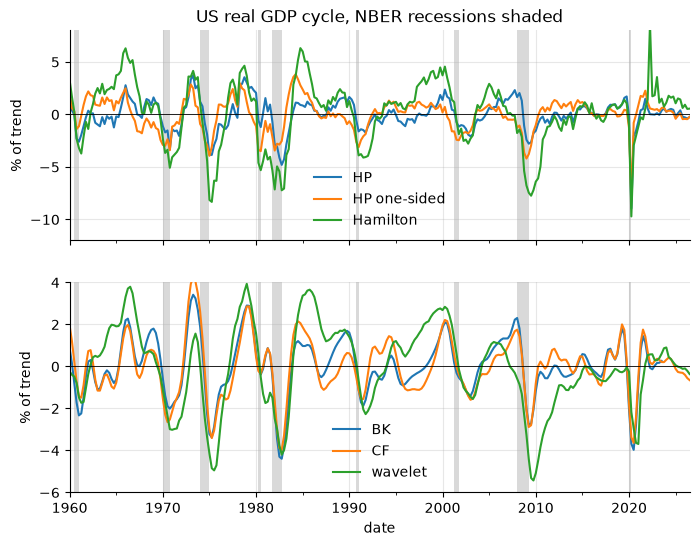

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
cycles.loc["1960":, ["HP", "HP one-sided", "Hamilton"]].plot(ax=axes[0])
cycles.loc["1960":, ["BK", "CF", "wavelet"]].plot(ax=axes[1])
for ax in axes:
    shade_recessions(ax)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylabel("% of trend")
axes[0].set_ylim(-12, 8)
axes[1].set_ylim(-6, 4)
axes[0].set_title("US real GDP cycle, NBER recessions shaded")

The one-sided HP correlates only 0.5 with the two-sided one: the same
filter tells a different story in real time. In 2007, the one-sided HP said
output was slightly below trend; with hindsight, the two-sided filter puts it
about 2% above. And this understates the problem: true real-time estimates
would also use the GDP data as first published, before revisions. The
wavelet cycle, also one-sided, shows the other cost: it lags turning points
(see its 2009 trough in the figure above).

Text(0.5, 1.0, 'Output gap: with hindsight (HP) and in real time (one-sided HP)')

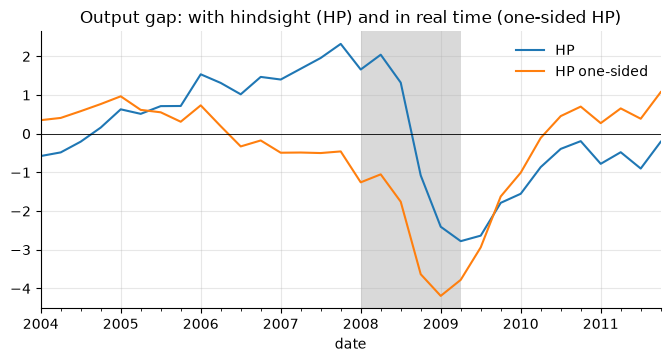

In [16]:
ax = cycles.loc["2004":"2011", ["HP", "HP one-sided"]].plot()
ax.axhline(0, color="k", lw=0.6)
shade_recessions(ax)
ax.set_title("Output gap: with hindsight (HP) and in real time (one-sided HP)")

## Which filter?

| Purpose | Use |
|---|---|
| Stylized facts, historical description | HP (two-sided), CF, BK; report two |
| Real-time gap, early warning (credit gap) | one-sided HP, Hamilton |
| Cycle with a specific periodicity | CF (full sample) or BK |
| Structural interpretation, uncertainty bands | UC model |
| Permanent vs transitory shocks | Beveridge–Nelson (bivariate, or the BN filter); Blanchard–Quah |
| Quick, one-sided frequency split | Haar wavelet |

## Pitfalls

* All two-sided filters revise their recent values as data arrive. Compare
  vintages before claiming the economy is "above potential".
* The 2020 collapse dominates every regression-based filter that includes
  it (Hamilton, BN, UC). The Hamilton cycle also **echoes** it $h$ quarters
  later: the 2022 spike in the figure is the 2020Q2 trough entering
  $y_{t-8}$. Estimate on pre-2020 data or add outlier dummies.
* Filters applied to non-logged data give cycles in levels, which grow with
  the series. Log first.
* A filter can create cycles from white noise (Slutsky effect; Cogley and
  Nason, 1995, for HP). Check that the stylized fact survives other filters.

## Summary

* Detrend **logs × 100**: the cycle is then in percent of trend.
* The two-sided HP filter is fine for describing history; it is **not**
  fine in real time. Use the one-sided HP or the Hamilton filter for
  anything that pretends to be known at time $t$.
* Band-pass filters (BK, CF) let you choose the periodicities: 6–32
  quarters is the standard business-cycle band.
* Report results for more than one filter.

## Exercises

1. Apply the HP filter (λ = 1600) to log real GDP × 100 (`GDPC1`) on 1960–2007 and on 1960–2019. How different is the 2007 output gap in the two runs, and what does this say about end-of-sample estimates?
2. Compute the two-sided HP, one-sided HP and Hamilton cycles of Portuguese real GDP (`CLVMNACSCAB1GQPT`, 1995–2019). Was output above or below trend in 2008Q1 and in 2011Q1 according to each, and which answers could a policymaker have had at the time?
3. Extract the business-cycle component of monthly log industrial production (`INDPRO`, 1960–2019) with Christiano–Fitzgerald (periods 18–96 months) and with HP (λ = 129600). Compare their standard deviations and correlation, and check which one moves more at the end of the sample.
4. Rerun the bivariate Beveridge–Nelson and Blanchard–Quah decompositions with 4 lags instead of 8 (1948–2019). Are both cycles still negative on average in NBER recessions (`USRECQ`), and what does the answer suggest about how much these decompositions depend on the lag choice?